# Q1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

## A.

In [2]:
# Começa em 0, vai até 10 pulando de 0.01 em 0.01
x = np.arange(0, 10.01, 0.01)
y = 3 * np.sin(2 * x) + 2 * np.cos(5 * x) + 0.5 * (x ** 2)
# scikit-learn foi programado para exigir sempre uma Tabela 2D
X = x.reshape(-1, 1)

# Separar em Treino (60%), Validação (20%) e Teste (20%)
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, random_state=42)

scaler_X = StandardScaler() # Z-score - Padronização
scaler_y = StandardScaler()

X_train_s = scaler_X.fit_transform(X_train)
X_val_s   = scaler_X.transform(X_val)
X_test_s  = scaler_X.transform(X_test)

y_train_s = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_val_s   = scaler_y.transform(y_val.reshape(-1, 1)).ravel()

In [3]:
from sklearn.model_selection import ParameterGrid

grid = {
    'hidden_layer_sizes': [(8,), (16, 8), (32, 16), (64, 64)],
    'alpha': [0.001, 0.01, 0.1, 1.0, 2.0]
}


historico_testes = []

for params in ParameterGrid(grid):

    mlp_temp = MLPRegressor(
        hidden_layer_sizes=params['hidden_layer_sizes'],
        alpha=params['alpha'],
        activation='tanh',
        solver='adam',
        learning_rate_init=0.002,
        max_iter=300,
        random_state=42
    )

    mlp_temp.fit(X_train_s, y_train_s)
    pred_val_s = mlp_temp.predict(X_val_s)
    pred_val_real = scaler_y.inverse_transform(pred_val_s.reshape(-1, 1)).ravel()

    mse_val = mean_squared_error(y_val, pred_val_real)
    mae_val = mean_absolute_error(y_val, pred_val_real)

    historico_testes.append({
        'Arquitetura': str(params['hidden_layer_sizes']),
        'Alpha (Regularização)': params['alpha'],
        'MSE (Validação)': mse_val,
        'MAE (Validação)': mae_val
    })

df_resultados = pd.DataFrame(historico_testes)
df_resultados = df_resultados.sort_values(by='MSE (Validação)').reset_index(drop=True)
display(df_resultados)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,Arquitetura,Alpha (Regularização),MSE (Validação),MAE (Validação)
0,"(64, 64)",0.100,6.620148,2.098114
1,"(64, 64)",0.001,6.630875,2.097020
2,"(64, 64)",0.010,6.640809,2.098299
3,"(64, 64)",1.000,7.011666,2.147750
4,"(32, 16)",1.000,7.113213,2.155055
5,"(32, 16)",0.001,7.555071,2.174406
6,"(32, 16)",0.010,7.559868,2.174875
7,"(32, 16)",0.100,7.610317,2.179942
8,"(16, 8)",2.000,7.616256,2.142199
9,"(32, 16)",2.000,7.705238,2.222290


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691

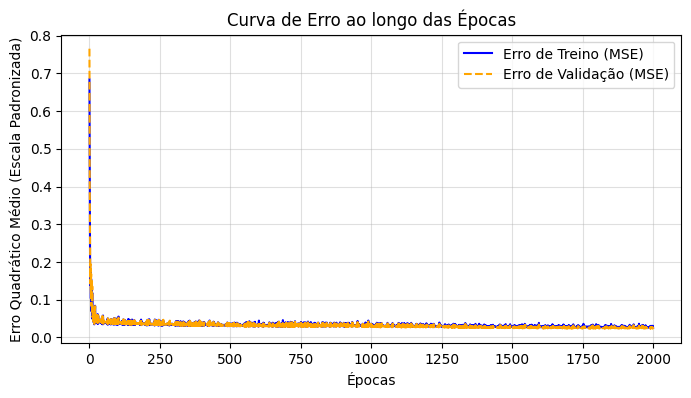

In [4]:
# Criar a MLP com 'adam' e 'warm_start=True' (para continuar de onde parou a cada época)
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 64),
    activation='tanh',
    solver='adam',
    learning_rate_init=0.01,
    alpha = 0.100,
    max_iter=1,        # Roda 1 época por vez dentro do for
    warm_start=True,   # Não apaga o que aprendeu na época anterior!
    random_state=42
)
# Listas para guardar o histórico de erros época por época
erro_treino = []
erro_val = []
epocas = 2000

# 5. Treinar época por época e anotar os dois erros
for epoca in range(epocas):
    mlp.fit(X_train_s, y_train_s)

    # Calcula o erro (MSE) no Treino e na Validação naquela época
    pred_train = mlp.predict(X_train_s)
    pred_val   = mlp.predict(X_val_s)

    erro_treino.append(mean_squared_error(y_train_s, pred_train))
    erro_val.append(mean_squared_error(y_val_s, pred_val))

# 6. Plotar a Curva de Erro de Treinamento vs. Validação
plt.figure(figsize=(8, 4))
plt.plot(erro_treino, label='Erro de Treino (MSE)', color='blue')
plt.plot(erro_val, label='Erro de Validação (MSE)', color='orange', linestyle='--')
plt.title('Curva de Erro ao longo das Épocas')
plt.xlabel('Épocas')
plt.ylabel('Erro Quadrático Médio (Escala Padronizada)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

MAE  (Erro Absoluto Médio):        0.3718
MSE  (Erro Quadrático Médio):      0.2224
RMSE (Raiz do Erro Quadrático):    0.4716


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.
  warnings.warn(


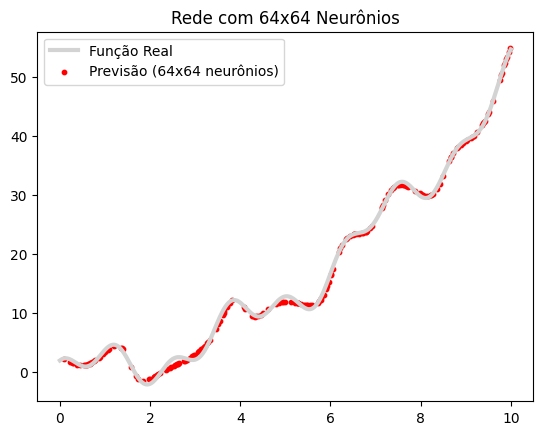

In [5]:
# Criar a rede com duas camadas de 64 neurônios
mlp_64 = MLPRegressor(
    hidden_layer_sizes=(64,64),
    activation='tanh',
    solver='adam',
    learning_rate_init=0.005,
    alpha = 0.001,
    tol=1e-6,                 # Não deixa parar o treino cedo demais!
    n_iter_no_change=50,
    max_iter=1500,
    random_state=42
)

# Treinar a rede
mlp_64.fit(X_train_s, y_train_s)

# Fazer a previsão do teste e voltar para a escala normal
y_pred_scaled_64 = mlp_64.predict(X_test_s)
y_pred_64 = scaler_y.inverse_transform(y_pred_scaled_64.reshape(-1, 1)).ravel()

#  Mostrar o erro e desenhar o gráfico simples
mae  = mean_absolute_error(y_test, y_pred_64)
mse  = mean_squared_error(y_test, y_pred_64)
rmse = np.sqrt(mse) # Raiz quadrada do MSE!

print(f"MAE  (Erro Absoluto Médio):        {mae:.4f}")
print(f"MSE  (Erro Quadrático Médio):      {mse:.4f}")
print(f"RMSE (Raiz do Erro Quadrático):    {rmse:.4f}")

plt.plot(x, y, color='lightgray', linewidth=3, label='Função Real')
plt.scatter(X_test, y_pred_64, color='red', s=10, label='Previsão (64x64 neurônios)')
plt.title("Rede com 64x64 Neurônios")
plt.legend()
plt.show()

## B.

In [6]:
from sklearn.datasets import load_diabetes
diabetes = load_diabetes(as_frame=True)
diabetes.target[:3]
diabetes.data.shape

(442, 10)

In [7]:
# age    : Idade do paciente (em anos, padronizada)
# sex    : Sexo biológico do paciente
# bmi    : Índice de Massa Corporal - IMC (Body Mass Index - peso/altura²)
# bp     : Pressão Arterial Média (Average Blood Pressure)
# s1     : Colesterol Total no sangue (TC - Total Serum Cholesterol)
# s2     : Colesterol LDL - "Colesterol Ruim" (Low-Density Lipoproteins)
# s3     : Colesterol HDL - "Colesterol Bom" (High-Density Lipoproteins)
# s4     : Relação Colesterol Total / HDL (TCH - Total Cholesterol / HDL)
# s5     : Nível de Triglicerídeos no sangue (LTG - Log of Serum Triglycerides)
# s6     : Nível de Glicose / Açúcar no sangue (GLU - Blood Sugar Level)

In [8]:
tabela = diabetes.frame
tabela.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [9]:
tabela.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


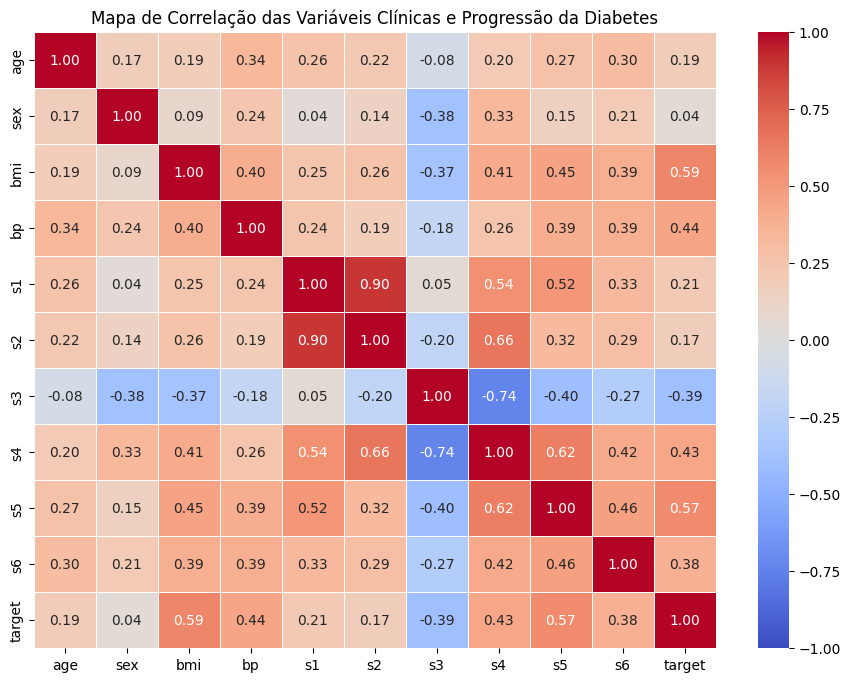

In [10]:
matriz_correlacao = tabela.corr()

plt.figure(figsize=(11, 8))


sns.heatmap(
    matriz_correlacao,
    annot=True,        # Escreve o número da correlação dentro de cada quadradinho
    fmt=".2f",         # Arredonda para 2 casas decimais
    cmap='coolwarm',   # Azul = correlação negativa | Vermelho = correlação positiva
    vmin=-1, vmax=1,   # Fixa a barra de cores entre -1 e +1
    linewidths=0.5     # Cria uma bordinha branca separando os quadrados
)

plt.title('Mapa de Correlação das Variáveis Clínicas e Progressão da Diabetes')
plt.show()

In [11]:
# Carregar a tabela completa (11 colunas: as 10 originais + a coluna 'target')
df = diabetes.frame

# Definir X (todas as 10 colunas restantes) e y (apenas o IMC / bmi)
X = df.drop(columns=['target']).values  # Matriz (442 linhas, 10 colunas)
y = df['target'].values                 # Vetor (442,) -> O IMC que queremos prever!

print("Formato de X (Entradas):", X.shape) # Vai mostrar (442, 10)
print("Formato de y (Saída IMC):", y.shape) # Vai mostrar (442,)

# Divisão em Treino (60%), Validação (20%) e Teste (20%)
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val   = train_test_split(X_resto, y_resto, test_size=0.25, random_state=42)

# Padronização (Muito importante aqui porque a coluna 'target' vai até 346 e as outras vão de -0.1 a +0.1!)
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_s = scaler_X.fit_transform(X_train)
X_val_s   = scaler_X.transform(X_val)
X_test_s  = scaler_X.transform(X_test)

y_train_s = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_val_s   = scaler_y.transform(y_val.reshape(-1, 1)).ravel()

Formato de X (Entradas): (442, 10)
Formato de y (Saída IMC): (442,)


In [12]:
# melhores Hiperparametros
from sklearn.model_selection import ParameterGrid

grid = {
    'hidden_layer_sizes': [(8,), (16, 8), (32, 16), (64, 64)],
    'alpha': [0.001, 0.01, 0.1, 1.0, 2.0]
}

historico_testes = []

for params in ParameterGrid(grid):

    mlp_temp = MLPRegressor(
        hidden_layer_sizes=params['hidden_layer_sizes'],
        alpha=params['alpha'],
        activation='tanh',
        solver='adam',
        learning_rate_init=0.002,
        max_iter=300,
        random_state=42
    )


    mlp_temp.fit(X_train_s, y_train_s)
    pred_val_s = mlp_temp.predict(X_val_s)
    pred_val_real = scaler_y.inverse_transform(pred_val_s.reshape(-1, 1)).ravel()


    mse_val = mean_squared_error(y_val, pred_val_real)
    mae_val = mean_absolute_error(y_val, pred_val_real)

    historico_testes.append({
        'Arquitetura': str(params['hidden_layer_sizes']),
        'Alpha (Regularização)': params['alpha'],
        'MSE (Validação)': mse_val,
        'MAE (Validação)': mae_val
    })

df_resultados = pd.DataFrame(historico_testes)
df_resultados = df_resultados.sort_values(by='MSE (Validação)').reset_index(drop=True)
display(df_resultados)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

,Arquitetura,Alpha (Regularização),MSE (Validação),MAE (Validação)
0,"(64, 64)",1.000,2399.569333,39.778571
1,"(8,)",1.000,2494.086305,40.393545
2,"(8,)",2.000,2547.512626,41.336799
3,"(16, 8)",2.000,2584.309913,42.082377
4,"(32, 16)",2.000,2587.032082,41.927684
5,"(64, 64)",2.000,2599.668634,42.290373
6,"(8,)",0.100,2623.968086,41.287006
7,"(8,)",0.010,2644.326766,41.445466
8,"(8,)",0.001,2645.892605,41.463981
9,"(32, 16)",1.000,2672.713756,42.274483


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691

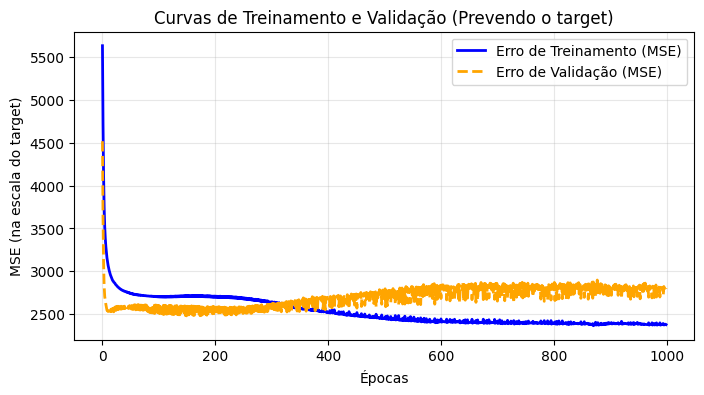

In [13]:
# Arquitetura: 10 entradas -> 16 neurônios -> 8 neurônios -> 1 saída (IMC)
mlp = MLPRegressor(
    hidden_layer_sizes=(32,16),
    activation='tanh',
    solver='adam',
    learning_rate_init=0.002,
    alpha=2.0,           # Evita que a rede decore os pacientes (regularização)
    max_iter=1,
    warm_start=True,
    random_state=42
)

erro_treino = []
erro_val = []
epocas = 1000

for epoca in range(epocas):
    mlp.fit(X_train_s, y_train_s)

    # Previsão e retorno para a escala do IMC
    pred_train = scaler_y.inverse_transform(mlp.predict(X_train_s).reshape(-1, 1)).ravel()
    pred_val   = scaler_y.inverse_transform(mlp.predict(X_val_s).reshape(-1, 1)).ravel()

    erro_treino.append(mean_squared_error(y_train, pred_train))
    erro_val.append(mean_squared_error(y_val, pred_val))

# Curvas de Treinamento e Validação
plt.figure(figsize=(8, 4))
plt.plot(erro_treino, label='Erro de Treinamento (MSE)', color='blue', linewidth=2)
plt.plot(erro_val, label='Erro de Validação (MSE)', color='orange', linestyle='--', linewidth=2)
plt.title('Curvas de Treinamento e Validação (Prevendo o target)')
plt.xlabel('Épocas')
plt.ylabel('MSE (na escala do target)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
# Criamos uma NOVA rede MLP do zero usando a 'melhor_epoca' descoberta na validação!
mlp_32 = MLPRegressor(
    hidden_layer_sizes=(16,32),
    activation='tanh',
    solver='adam',
    learning_rate_init=0.002,
    alpha=2.00,
    max_iter = 1000,
    random_state=42
)

#  já separou 80% no 'X_resto' e 20% no 'X_test'!
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler_X_final = StandardScaler()
scaler_y_final = StandardScaler()

X_resto_s = scaler_X_final.fit_transform(X_resto) # Ajusta nos 353 pacientes (80%)
X_test_s  = scaler_X_final.transform(X_test)      # Aplica nos 89 pacientes do Teste (20%)

y_resto_s = scaler_y_final.fit_transform(y_resto.reshape(-1, 1)).ravel()

# Treina de uma vez só!
mlp_32.fit(X_train_s, y_train_s)

# Testa no conjunto de Teste Final
y_pred_s = mlp_32.predict(X_test_s)
y_pred = scaler_y.inverse_transform(y_pred_s.reshape(-1, 1)).ravel()


mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=== RESULTADO DO NOVO MLP_FINAL NO TESTE ===")
print(f"Épocas usadas no treino: {400}")
print(f"MAE  (Erro Absoluto Médio):     {mae:.5f}")
print(f"MSE  (Erro Quadrático Médio):   {mse:.5f}")
print(f"RMSE (Raiz do Erro Quadrático): {rmse:.5f}")

=== RESULTADO DO NOVO MLP_FINAL NO TESTE ===
Épocas usadas no treino: 400
MAE  (Erro Absoluto Médio):     41.06217
MSE  (Erro Quadrático Médio):   2671.43780
RMSE (Raiz do Erro Quadrático): 51.68595


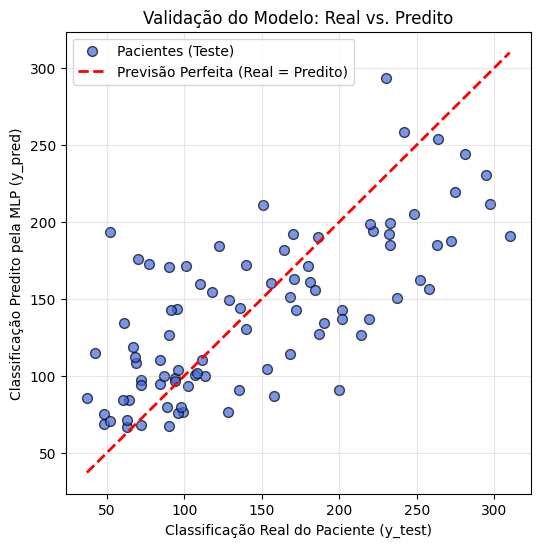

In [16]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, color='royalblue', alpha=0.7, edgecolors='k', s=50, label='Pacientes (Teste)')
limites = [y_test.min() - 0.01, y_test.max() + 0.01]
plt.plot(limites, limites, color='red', linestyle='--', linewidth=2, label='Previsão Perfeita (Real = Predito)')
plt.title('Validação do Modelo: Real vs. Predito')
plt.xlabel('Classificação Real do Paciente (y_test)')
plt.ylabel('Classificação Predito pela MLP (y_pred)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Q2

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,log_loss
from imblearn.over_sampling import SMOTE

In [18]:
pip install ucimlrepo

In [19]:
from ucimlrepo import fetch_ucirepo

wine_quality = fetch_ucirepo(id=186)

X = wine_quality.data.features
y = wine_quality.data.targets

df = pd.concat([X,y],axis=1)
df


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7


In [20]:
def niveis_quality(q):
    if q <= 4:
        return 'baixa'
    elif q <= 6:
        return 'media'
    else:
        return 'alta'

df['quality_cat'] = df['quality'].apply(niveis_quality)

print("Distribuição das categorias de qualidade:")
print(df['quality_cat'].value_counts())

Distribuição das categorias de qualidade:
quality_cat
media    4974
alta     1277
baixa     246
Name: count, dtype: int64


In [21]:
print("Valores ausentes: ")
print(df.isnull().sum())

Valores ausentes: 
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
quality_cat             0
dtype: int64


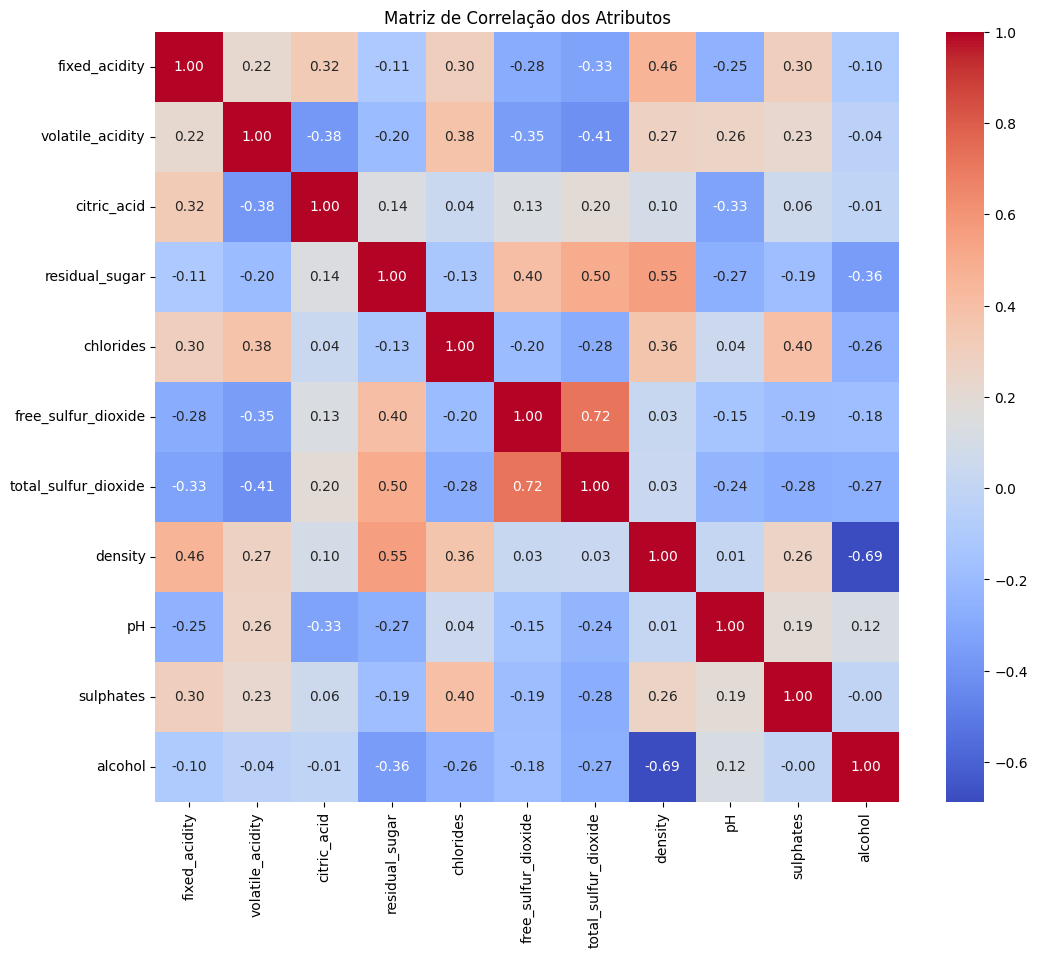

In [24]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.drop(['quality','quality_cat'],axis=1).corr(),annot=True,cmap='coolwarm',fmt=".2f")
plt.title('Matriz de Correlação dos Atributos')
plt.show()

In [25]:
features = X.columns
X_features = df.drop(['quality', 'quality_cat'], axis=1)
y_target = df['quality_cat']
scaler = StandardScaler()
X_normalized = scaler.fit_transform(X_features)

X_normalized

array([[ 0.14247327,  2.18883292, -2.19283252, ...,  1.81308951,
         0.19309677, -0.91546416],
       [ 0.45103572,  3.28223494, -2.19283252, ..., -0.11507303,
         0.99957862, -0.58006813],
       [ 0.45103572,  2.55330026, -1.91755268, ...,  0.25811972,
         0.79795816, -0.58006813],
       ...,
       [-0.55179227, -0.6054167 , -0.88525328, ..., -1.42124765,
        -0.47897144, -0.91546416],
       [-1.32319841, -0.30169391, -0.12823371, ...,  0.75571005,
        -1.016626  ,  1.9354021 ],
       [-0.93749534, -0.78765037,  0.42232597, ...,  0.25811972,
        -1.41986693,  1.09691202]], shape=(6497, 11))

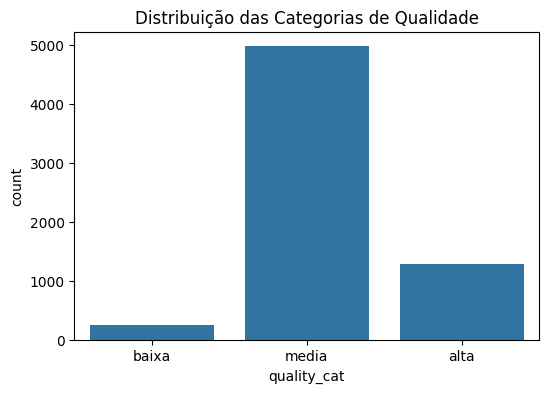

In [26]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df,x='quality_cat',order=['baixa','media','alta'])
plt.title('Distribuição das Categorias de Qualidade')
plt.show()

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2, random_state=42, stratify=y_target)

In [29]:
smote = SMOTE(random_state=42)
X_balanceado, y_balanceado = smote.fit_resample(X_train, y_train)

print("Distribuição das categorias de qualidade antes do balanceamento:")
print(df['quality_cat'].value_counts())

print("Distribuição das categorias de qualidade após o balanceamento:")
print(pd.Series(y_balanceado).value_counts())

Distribuição das categorias de qualidade antes do balanceamento:
quality_cat
media    4974
alta     1277
baixa     246
Name: count, dtype: int64
Distribuição das categorias de qualidade após o balanceamento:
quality_cat
media    3979
alta     3979
baixa    3979
Name: count, dtype: int64


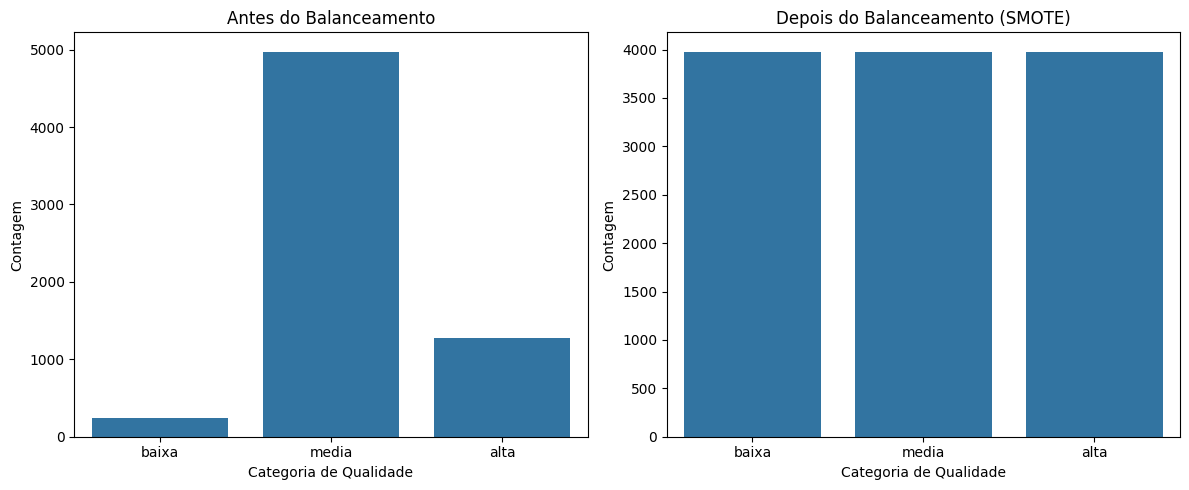

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='quality_cat', order=['baixa', 'media', 'alta'], ax=axes[0])
axes[0].set_title('Antes do Balanceamento')
axes[0].set_xlabel('Categoria de Qualidade')
axes[0].set_ylabel('Contagem')

sns.countplot(x=y_balanceado, order=['baixa', 'media', 'alta'], ax=axes[1])
axes[1].set_title('Depois do Balanceamento (SMOTE)')
axes[1].set_xlabel('Categoria de Qualidade')
axes[1].set_ylabel('Contagem')

plt.tight_layout()
plt.show()

In [31]:
X_final = X_balanceado
y_final = y_balanceado

In [33]:
mlp = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    max_iter=1,
    warm_start=True,
    random_state=42)

n_epochs = 100
train_loss_curve = []
val_loss_curve = []

for epoch in range(n_epochs):
  mlp.partial_fit(X_train, y_train, classes=np.unique(y_train))
  train_loss_curve.append(mlp.loss_)
  y_proba_val = mlp.predict_proba(X_test)
  val_loss = log_loss(y_test, y_proba_val, labels=mlp.classes_)
  val_loss_curve.append(val_loss)

  if (epoch + 1) % 10 == 0:
    print(f"Época {epoch+1:3d}/{n_epochs} | Erro Treino: {train_loss_curve[-1]:.4f} | Erro Validação: {val_loss:.4f}")

Época  10/100 | Erro Treino: 0.5810 | Erro Validação: 0.5911
Época  20/100 | Erro Treino: 0.5612 | Erro Validação: 0.5737
Época  30/100 | Erro Treino: 0.5498 | Erro Validação: 0.5650
Época  40/100 | Erro Treino: 0.5424 | Erro Validação: 0.5590
Época  50/100 | Erro Treino: 0.5349 | Erro Validação: 0.5518
Época  60/100 | Erro Treino: 0.5296 | Erro Validação: 0.5457
Época  70/100 | Erro Treino: 0.5262 | Erro Validação: 0.5449
Época  80/100 | Erro Treino: 0.5219 | Erro Validação: 0.5374
Época  90/100 | Erro Treino: 0.5185 | Erro Validação: 0.5334
Época 100/100 | Erro Treino: 0.5147 | Erro Validação: 0.5332


In [34]:
print(f"Camadas ocultas: {mlp.hidden_layer_sizes}")
print(f"Função de ativação: {mlp.activation}")
print(f"Solver: {mlp.solver}")
print(f"Número de épocas: {n_epochs}")
print(f"Neurônios na entrada (quantidade de atributos): {mlp.n_features_in_}")
print(f"Neurônios na saída (classes): {mlp.classes_}")

Camadas ocultas: (100, 50)
Função de ativação: relu
Solver: adam
Número de épocas: 100
Neurônios na entrada (quantidade de atributos): 11
Neurônios na saída (classes): ['alta' 'baixa' 'media']


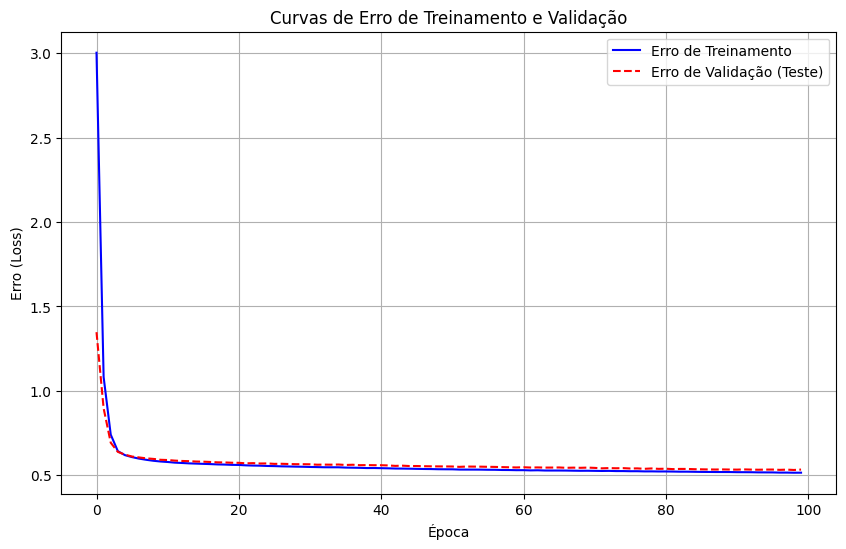

In [35]:
plt.figure(figsize=(10, 6))

plt.plot(train_loss_curve, label='Erro de Treinamento', color='blue')
plt.plot(val_loss_curve, label='Erro de Validação (Teste)', color='red', linestyle='--')
plt.title('Curvas de Erro de Treinamento e Validação')
plt.xlabel('Época')
plt.ylabel('Erro (Loss)')
plt.legend()
plt.grid(True)
plt.show()

In [37]:
y_pred = mlp.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=['baixa', 'media', 'alta'])

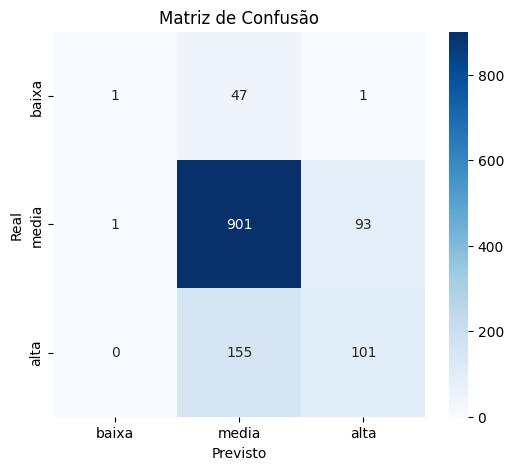

In [38]:
plt.figure(figsize=(6, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['baixa', 'media', 'alta'],
            yticklabels=['baixa', 'media', 'alta'])
plt.title('Matriz de Confusão')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.show()

In [39]:
print(f"Acurácia:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisão:  {precision_score(y_test, y_pred, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, average='weighted'):.4f}")

Acurácia:  0.7715
Precisão:  0.7461
Recall:    0.7715
F1-Score:  0.7471


# Q3.

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

# Reprodutibilidade dos experimentos
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU disponível:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponível: []


In [41]:
# Carregando a base CIFAR-10
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Nomes das classes
class_names = [
    "avião", "automóvel", "pássaro", "gato", "veado",
    "cachorro", "sapo", "cavalo", "navio", "caminhão"
]

print("Formato das imagens de treinamento:", x_train_full.shape)
print("Formato dos rótulos de treinamento:", y_train_full.shape)

print("Formato das imagens de teste:", x_test.shape)
print("Formato dos rótulos de teste:", y_test.shape)

print("Classes:", class_names)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 340s 2us/step
Formato das imagens de treinamento: (50000, 32, 32, 3)
Formato dos rótulos de treinamento: (50000, 1)
Formato das imagens de teste: (10000, 32, 32, 3)
Formato dos rótulos de teste: (10000, 1)
Classes: ['avião', 'automóvel', 'pássaro', 'gato', 'veado', 'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']


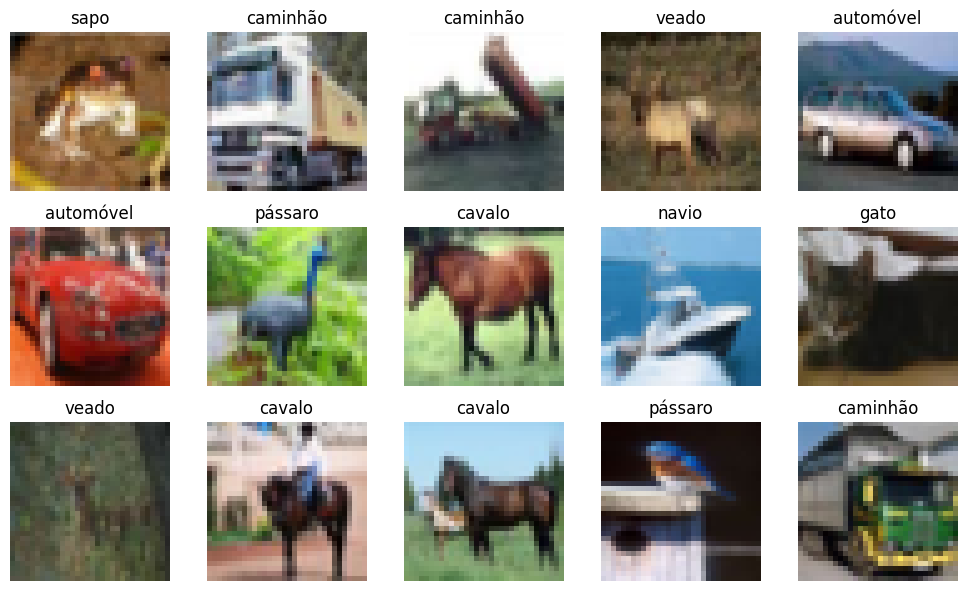

In [42]:
plt.figure(figsize=(10, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_train_full[i])

    label = y_train_full[i][0]
    plt.title(class_names[label])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [43]:
# Separação dos dados de treinamento e validação
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.1,
    random_state=SEED,
    stratify=y_train_full
)

# Normalização dos pixels
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Conferindo os conjuntos
print("Treinamento:", x_train.shape)
print("Validação:", x_val.shape)
print("Teste:", x_test.shape)

print("Menor valor de pixel:", x_train.min())
print("Maior valor de pixel:", x_train.max())

Treinamento: (45000, 32, 32, 3)
Validação: (5000, 32, 32, 3)
Teste: (10000, 32, 32, 3)
Menor valor de pixel: 0.0
Maior valor de pixel: 1.0


In [ ]:
# Construção da arquitetura MLP
mlp_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    layers.Flatten(),

    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

# Configuração do treinamento
mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Exibição da arquitetura
mlp_model.summary()

# Configuração da parada antecipada
early_stopping_mlp = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Construção da arquitetura CNN
cnn_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    # Primeiro bloco convolucional
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Segundo bloco convolucional
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Terceiro bloco convolucional
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Camadas totalmente conectadas
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Saída com 10 classes
    layers.Dense(10, activation="softmax")
])

# Configuração do treinamento
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Exibição da arquitetura
cnn_model.summary()

# Configuração da parada antecipada
early_stopping_cnn = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 6, 6, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 288,298 (1.10 MB)

 Trainable params: 288,298 (1.10 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Treinamento do MLP
print("========== TREINAMENTO DO MLP ==========")

history_mlp = mlp_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=[early_stopping_mlp],
    verbose=1
)

# Treinamento da CNN
print("\n========== TREINAMENTO DA CNN ==========")

history_cnn = cnn_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=[early_stopping_cnn],
    verbose=1
)

# Salvando os modelos treinados
mlp_model.save("mlp_cifar10.keras")
cnn_model.save("cnn_cifar10.keras")

# Salvando os históricos de treinamento
import pandas as pd

pd.DataFrame(history_mlp.history).to_csv(
    "historico_mlp.csv", index=False
)

pd.DataFrame(history_cnn.history).to_csv(
    "historico_cnn.csv", index=False
)

print("\nTreinamento dos dois modelos finalizado!")

========== TREINAMENTO DO MLP ==========
Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 30s 74ms/step - accuracy: 0.2497 - loss: 2.0380 - val_accuracy: 0.3308 - val_loss: 1.8634
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 30s 44ms/step - accuracy: 0.3019 - loss: 1.9040 - val_accuracy: 0.3518 - val_loss: 1.8067
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - accuracy: 0.3227 - loss: 1.8516 - val_accuracy: 0.3756 - val_loss: 1.7862
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.3340 - loss: 1.8266 - val_accuracy: 0.3862 - val_loss: 1.7357
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - accuracy: 0.3492 - loss: 1.7897 - val_accuracy: 0.3806 - val_loss: 1.7520
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/step - accuracy: 0.3480 - loss: 1.7836 - val_accuracy: 0.3966 - val_loss: 1.7145
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - accuracy: 0.3591 - loss: 1.7667 - val_accuracy: 0.4126 - val_loss: 1.6906
Epoch 8/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/

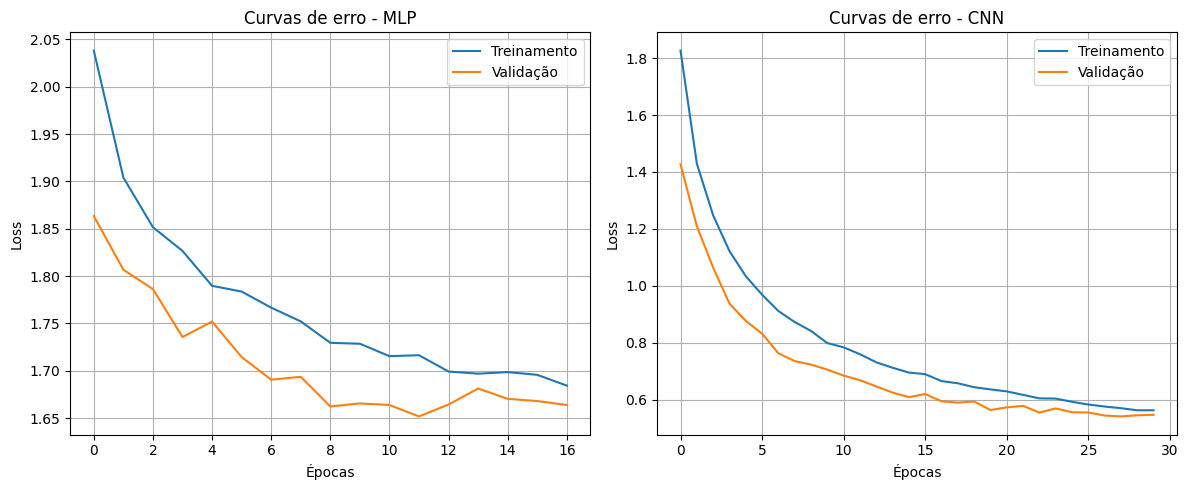

In [ ]:
# Curvas de erro dos dois modelos
plt.figure(figsize=(12, 5))

# MLP
plt.subplot(1, 2, 1)
plt.plot(history_mlp.history["loss"], label="Treinamento")
plt.plot(history_mlp.history["val_loss"], label="Validação")
plt.title("Curvas de erro - MLP")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# CNN
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Treinamento")
plt.plot(history_cnn.history["val_loss"], label="Validação")
plt.title("Curvas de erro - CNN")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Acurácia MLP: 42.07%
Acurácia CNN: 79.59%


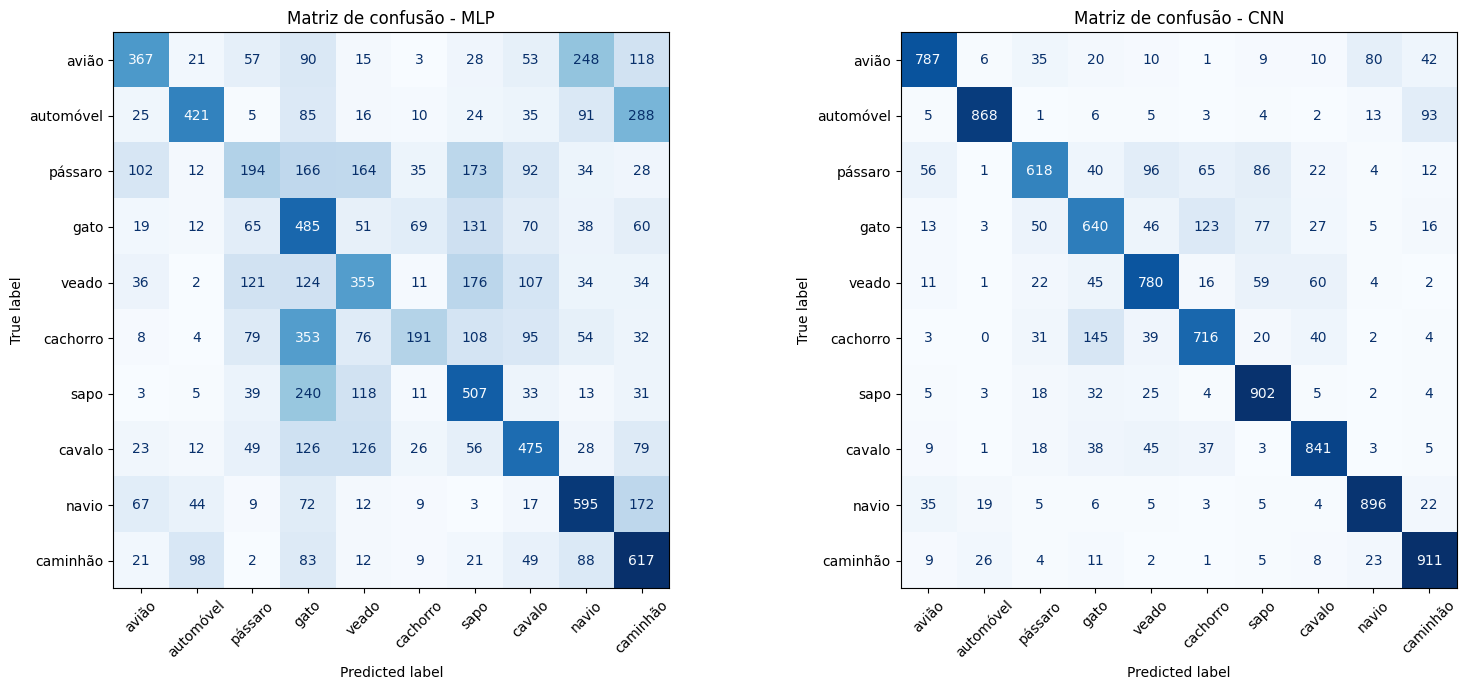

In [ ]:
# Avaliação dos modelos
mlp_loss, mlp_accuracy = mlp_model.evaluate(
    x_test, y_test, verbose=0
)

cnn_loss, cnn_accuracy = cnn_model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Acurácia MLP: {mlp_accuracy * 100:.2f}%")
print(f"Acurácia CNN: {cnn_accuracy * 100:.2f}%")

# Previsões dos modelos
y_pred_mlp = np.argmax(
    mlp_model.predict(x_test, verbose=0), axis=1
)

y_pred_cnn = np.argmax(
    cnn_model.predict(x_test, verbose=0), axis=1
)

# Matrizes de confusão
cm_mlp = confusion_matrix(y_test.flatten(), y_pred_mlp)
cm_cnn = confusion_matrix(y_test.flatten(), y_pred_cnn)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=class_names
).plot(ax=axes[0], cmap="Blues", xticks_rotation=45, colorbar=False)

axes[0].set_title("Matriz de confusão - MLP")

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=class_names
).plot(ax=axes[1], cmap="Blues", xticks_rotation=45, colorbar=False)

axes[1].set_title("Matriz de confusão - CNN")

plt.tight_layout()
plt.show()

Total de imagens encontradas: 4


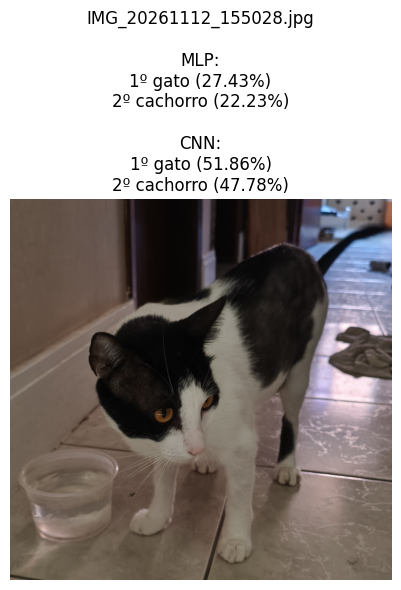

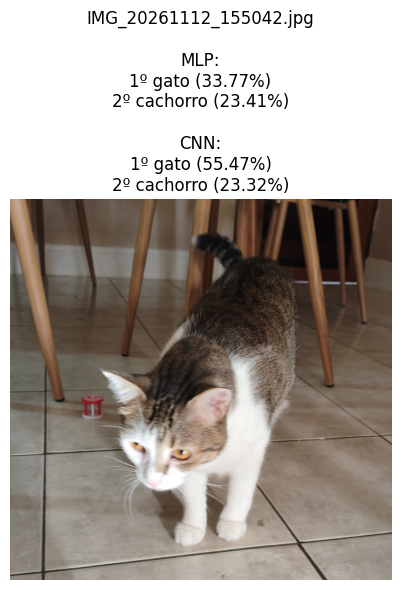

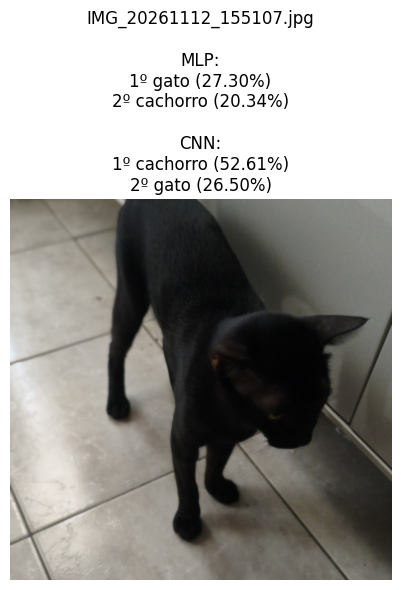

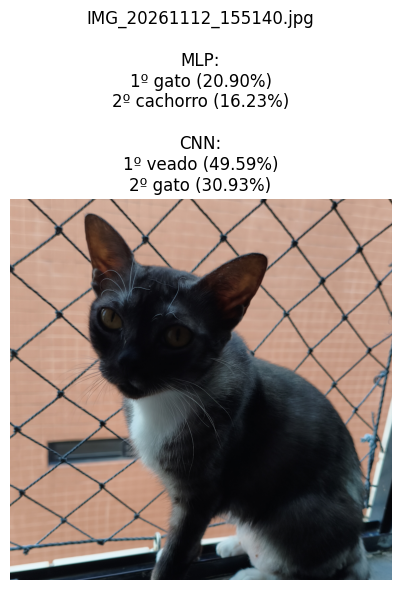

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import zipfile

# Caminho do ZIP
zip_path = "/content/Imagens_teste.zip"
pasta_destino = Path("/content/Imagens_extraidas")

# Extrair imagens
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(pasta_destino)

# Encontrar imagens, inclusive em subpastas
extensoes = {".jpg", ".jpeg", ".png", ".webp"}

imagens = sorted([
    arquivo for arquivo in pasta_destino.rglob("*")
    if arquivo.is_file() and arquivo.suffix.lower() in extensoes
])

print(f"Total de imagens encontradas: {len(imagens)}")

# Classificar uma imagem por vez
for caminho in imagens:
    img = Image.open(caminho).convert("RGB")

    # Preparar para os modelos
    img_resized = img.resize((32, 32))
    img_array = np.array(img_resized, dtype="float32") / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Previsões
    pred_mlp = mlp_model.predict(img_array, verbose=0)[0]
    pred_cnn = cnn_model.predict(img_array, verbose=0)[0]

    # Duas classes mais prováveis, em ordem decrescente
    top2_mlp = np.argsort(pred_mlp)[-2:][::-1]
    top2_cnn = np.argsort(pred_cnn)[-2:][::-1]

    # Mostrar imagem e resultados
    plt.figure(figsize=(7, 6))
    plt.imshow(img)
    plt.axis("off")

    plt.title(
        f"{caminho.name}\n\n"
        f"MLP:\n"
        f"1º {class_names[top2_mlp[0]]} "
        f"({pred_mlp[top2_mlp[0]]*100:.2f}%)\n"
        f"2º {class_names[top2_mlp[1]]} "
        f"({pred_mlp[top2_mlp[1]]*100:.2f}%)\n\n"
        f"CNN:\n"
        f"1º {class_names[top2_cnn[0]]} "
        f"({pred_cnn[top2_cnn[0]]*100:.2f}%)\n"
        f"2º {class_names[top2_cnn[1]]} "
        f"({pred_cnn[top2_cnn[1]]*100:.2f}%)"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

pasta = Path("/content/drive/MyDrive/modelos_cifar10")
pasta.mkdir(parents=True, exist_ok=True)

mlp_model.save(pasta / "mlp_cifar10.keras")
cnn_model.save(pasta / "cnn_cifar10.keras")

print("Modelos salvos no Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modelos salvos no Google Drive!


# Q4.

## A.

In [ ]:
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# Recuperar o modelo treinado, caso necessário
# cnn_model = keras.models.load_model(
#     "/content/drive/MyDrive/modelos_cifar10/cnn_cifar10.keras"
# )

# Selecionar a primeira camada convolucional
primeira_conv = next(
    camada for camada in cnn_model.layers
    if isinstance(camada, keras.layers.Conv2D)
)

# Extrair os pesos aprendidos
filtros, vieses = primeira_conv.get_weights()

print("Camada:", primeira_conv.name)
print("Formato dos filtros:", filtros.shape)
print("Quantidade de filtros:", filtros.shape[-1])

Camada: conv2d_5
Formato dos filtros: (3, 3, 3, 32)
Quantidade de filtros: 32


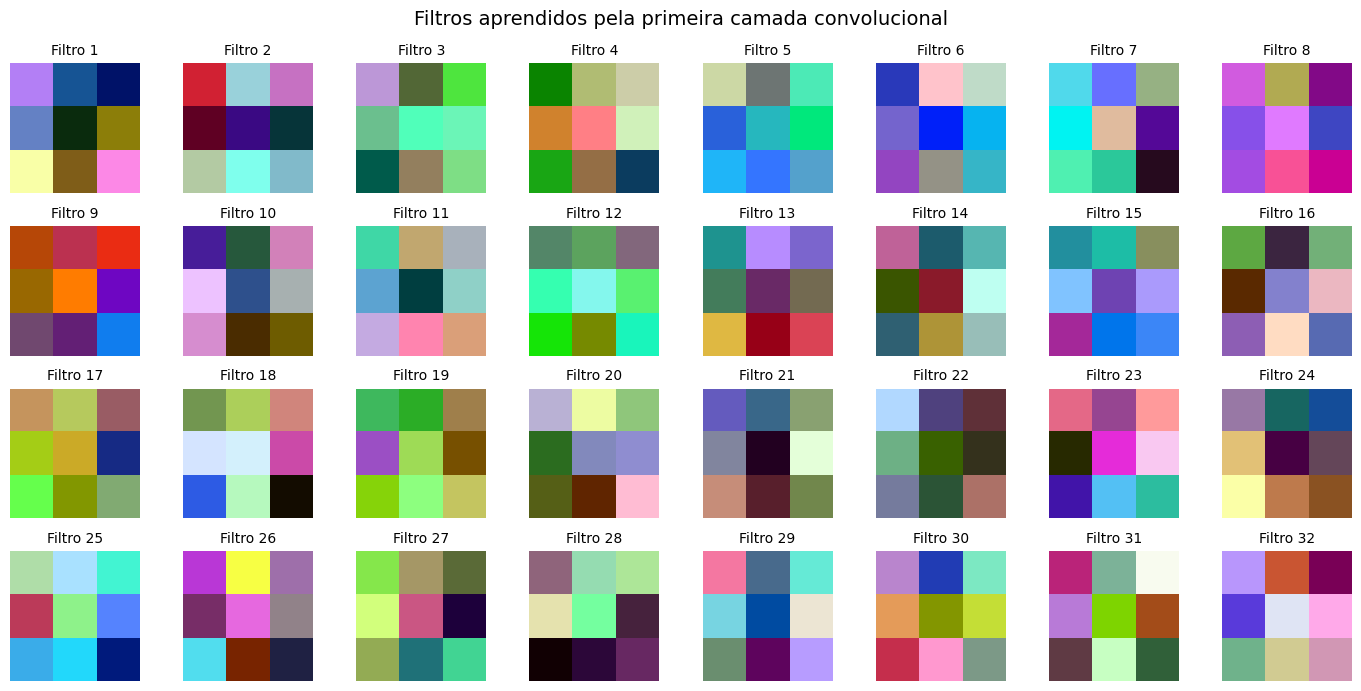

In [ ]:
fig, axes = plt.subplots(4, 8, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    filtro = filtros[:, :, :, i]

    # Normalização individual para visualização
    minimo = filtro.min()
    maximo = filtro.max()

    filtro_norm = (filtro - minimo) / (maximo - minimo + 1e-8)

    ax.imshow(filtro_norm, interpolation="nearest")
    ax.set_title(f"Filtro {i + 1}", fontsize=10)
    ax.axis("off")

plt.suptitle(
    "Filtros aprendidos pela primeira camada convolucional",
    fontsize=14
)

plt.tight_layout()
plt.show()

## B.

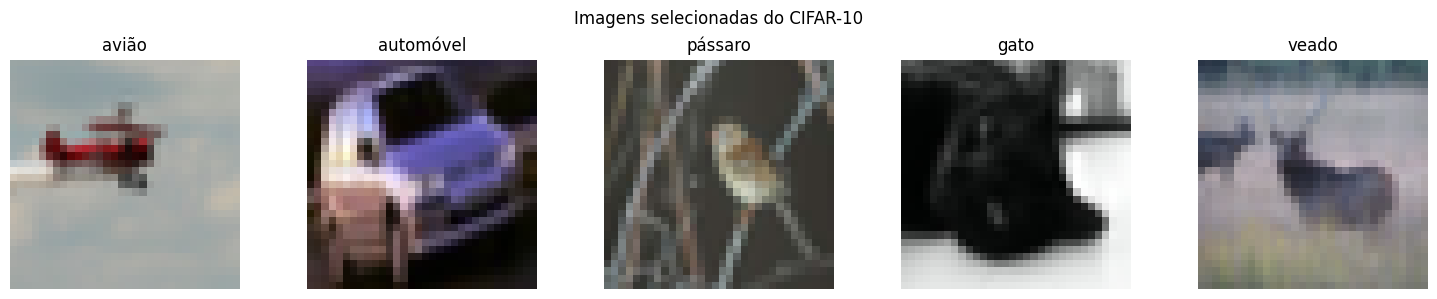

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Selecionar cinco imagens de classes diferentes
classes_selecionadas = [0, 1, 2, 3, 4]

indices = [
    np.random.choice(np.where(y_test.flatten() == classe)[0])
    for classe in classes_selecionadas
]

imagens = x_test[indices]
rotulos = y_test.flatten()[indices]

# Visualizar as imagens selecionadas
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i, ax in enumerate(axes):
    ax.imshow(imagens[i])
    ax.set_title(class_names[rotulos[i]])
    ax.axis("off")

plt.suptitle("Imagens selecionadas do CIFAR-10")
plt.tight_layout()
plt.show()

In [ ]:
camadas_conv = [
    camada for camada in cnn_model.layers
    if isinstance(camada, keras.layers.Conv2D)
]

for i, camada in enumerate(camadas_conv):
    print(
        f"{i}: {camada.name} | "
        f"Filtros: {camada.filters} | "
        f"Kernel: {camada.kernel_size}"
    )

# Selecionar a camada convolucional intermediária
camada_intermediaria = camadas_conv[len(camadas_conv) // 2]

print("\nCamada selecionada:", camada_intermediaria.name)

0: conv2d_5 | Filtros: 32 | Kernel: (3, 3)
1: conv2d_6 | Filtros: 32 | Kernel: (3, 3)
2: conv2d_7 | Filtros: 64 | Kernel: (3, 3)
3: conv2d_8 | Filtros: 64 | Kernel: (3, 3)
4: conv2d_9 | Filtros: 128 | Kernel: (3, 3)

Camada selecionada: conv2d_7


In [ ]:
from tensorflow import keras

# Garantir que a CNN tenha um tensor de entrada definido
entrada = keras.Input(shape=x_test.shape[1:])
saida = cnn_model(entrada)

# Modelo auxiliar para acessar as camadas internas
modelo_camadas = keras.Model(
    inputs=cnn_model.inputs,
    outputs=camada_intermediaria.output
)

# Extrair ativações das cinco imagens
mapas_ativacao = modelo_camadas.predict(imagens, verbose=0)

print("Formato dos mapas:", mapas_ativacao.shape)

Formato dos mapas: (5, 15, 15, 64)


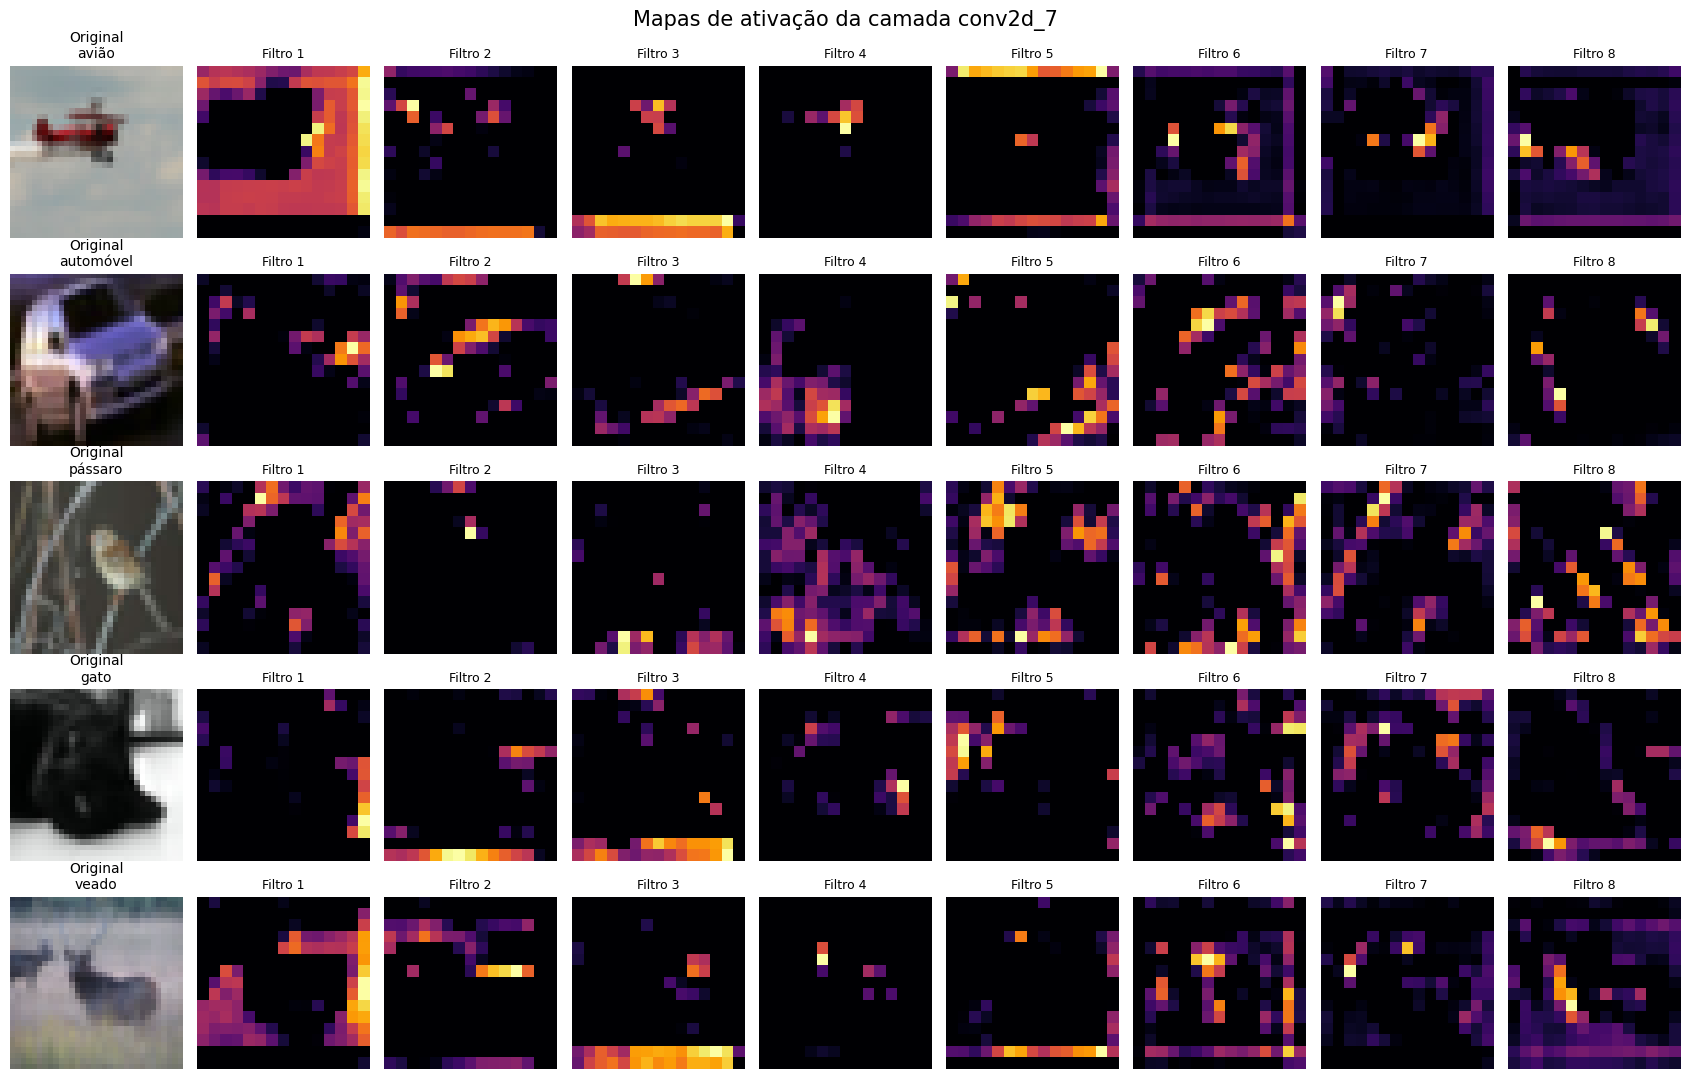

In [ ]:
fig, axes = plt.subplots(5, 9, figsize=(17, 11))

for i in range(5):
    # Imagem original
    axes[i, 0].imshow(imagens[i])
    axes[i, 0].set_title(
        f"Original\n{class_names[rotulos[i]]}",
        fontsize=10
    )
    axes[i, 0].axis("off")

    # Oito mapas de ativação
    for j in range(8):
        mapa = mapas_ativacao[i, :, :, j]

        axes[i, j + 1].imshow(
            mapa,
            cmap="inferno",
            interpolation="nearest"
        )

        axes[i, j + 1].set_title(
            f"Filtro {j + 1}",
            fontsize=9
        )
        axes[i, j + 1].axis("off")

plt.suptitle(
    "Mapas de ativação da camada conv2d_7",
    fontsize=15
)

plt.tight_layout()
plt.show()

## C.

In [67]:
# Obter as probabilidades previstas pela CNN
probabilidades = cnn_model.predict(x_test, verbose=0)

# Classe com maior probabilidade
predicoes = np.argmax(probabilidades, axis=1)

# Classes verdadeiras
verdadeiros = y_test.flatten()

# Identificar acertos e erros
indices_acertos = np.where(predicoes == verdadeiros)[0]
indices_erros = np.where(predicoes != verdadeiros)[0]

# Acurácia no conjunto de teste
acuracia = len(indices_acertos) / len(verdadeiros)

print(f"Total de imagens: {len(verdadeiros)}")
print(f"Classificações corretas: {len(indices_acertos)}")
print(f"Classificações incorretas: {len(indices_erros)}")
print(f"Acurácia: {acuracia:.2%}")

Total de imagens: 10000
Classificações corretas: 7959
Classificações incorretas: 2041
Acurácia: 79.59%


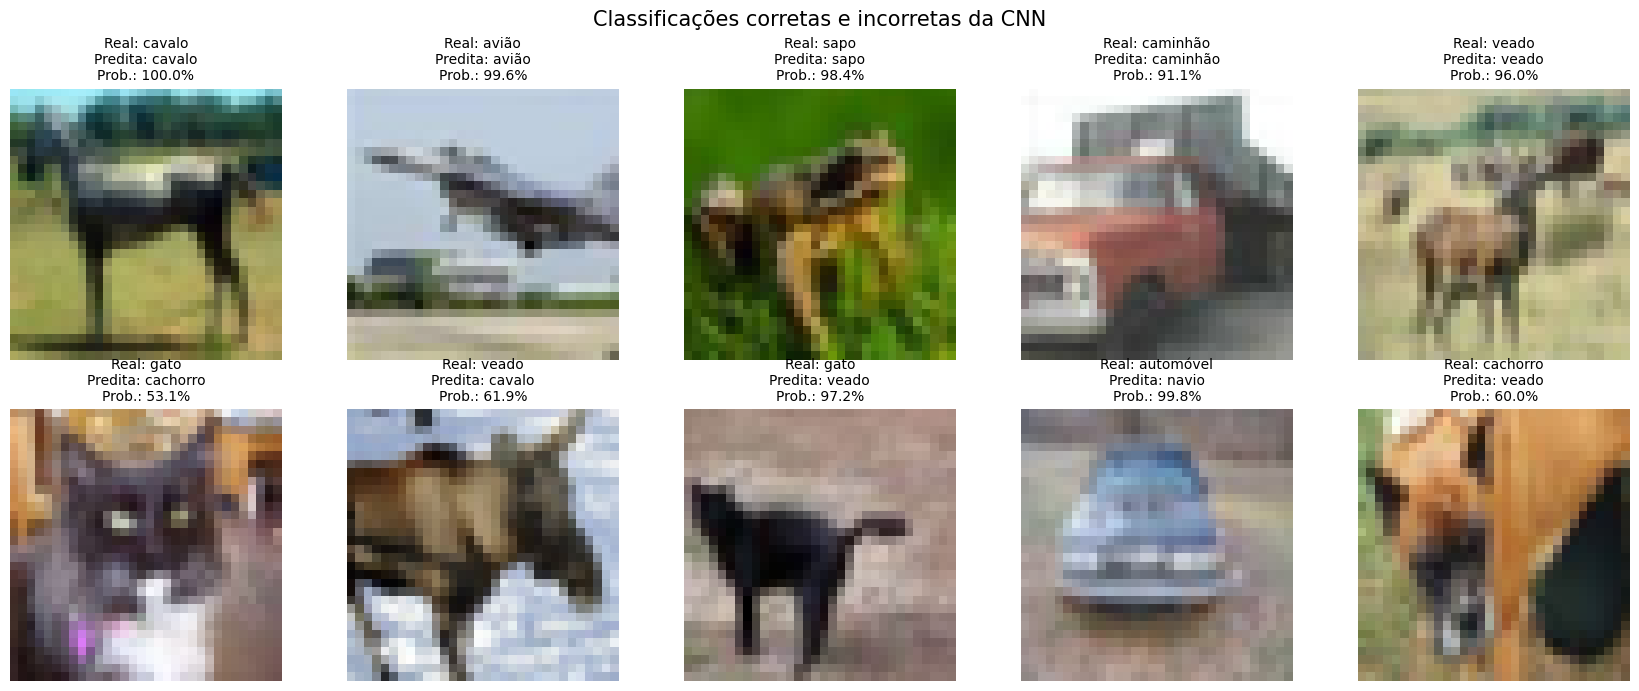

In [ ]:
rng = np.random.default_rng(42)

# Selecionar cinco exemplos de cada grupo
acertos = rng.choice(indices_acertos, size=5, replace=False)
erros = rng.choice(indices_erros, size=5, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(17, 7))

for linha, indices in enumerate([acertos, erros]):
    for coluna, idx in enumerate(indices):
        ax = axes[linha, coluna]

        # Imagem original
        ax.imshow(x_test[idx])

        classe_real = class_names[verdadeiros[idx]]
        classe_predita = class_names[predicoes[idx]]
        confianca = probabilidades[idx, predicoes[idx]] * 100

        ax.set_title(
            f"Real: {classe_real}\n"
            f"Predita: {classe_predita}\n"
            f"Prob.: {confianca:.1f}%",
            fontsize=10
        )

        ax.axis("off")

# Identificar os grupos
axes[0, 0].set_ylabel("Acertos", fontsize=13)
axes[1, 0].set_ylabel("Erros", fontsize=13)

plt.suptitle(
    "Classificações corretas e incorretas da CNN",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Q5

## A.

In [44]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

print(f"Treino: {len(train_dataset)}")
print(f"Teste: {len(test_dataset)}")

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 279kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.04MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.2MB/s]

Treino: 60000
Teste: 10000


In [45]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [46]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False)

indices = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
imgs_fixas = torch.stack([test_dataset[i][0] for i in indices]).to(device)

In [47]:
class AutoencoderDenso(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 100),
            nn.ReLU(),
            nn.Linear(100, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 100),
            nn.ReLU(),
            nn.Linear(100, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28))
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

In [48]:
def treinar(model, train_loader, epochs=15, lr=1e-3):
    model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        total = 0.0
        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad()
            x_hat, _ = model(x)
            loss = criterion(x_hat, x)
            loss.backward()
            optimizer.step()
            total += loss.item() * x.size(0)
        print(f"Época {ep+1:02d} | loss MSE: {total/len(train_loader.dataset):.6f}")

In [49]:
latent_dims = [100, 50, 30]
modelos = {}

for ld in latent_dims:
    print(f"\n=== Espaço latente = {ld} ===")
    m = AutoencoderDenso(ld)
    treinar(m, train_loader, epochs=15, lr=1e-3)
    modelos[ld] = m


=== Espaço latente = 100 ===
Época 01 | loss MSE: 0.039136
Época 02 | loss MSE: 0.020587
Época 03 | loss MSE: 0.017767
Época 04 | loss MSE: 0.016216
Época 05 | loss MSE: 0.015170
Época 06 | loss MSE: 0.014194
Época 07 | loss MSE: 0.013469
Época 08 | loss MSE: 0.012846
Época 09 | loss MSE: 0.012353
Época 10 | loss MSE: 0.011942
Época 11 | loss MSE: 0.011592
Época 12 | loss MSE: 0.011300
Época 13 | loss MSE: 0.011010
Época 14 | loss MSE: 0.010753
Época 15 | loss MSE: 0.010533

=== Espaço latente = 50 ===
Época 01 | loss MSE: 0.038654
Época 02 | loss MSE: 0.020604
Época 03 | loss MSE: 0.017855
Época 04 | loss MSE: 0.016365
Época 05 | loss MSE: 0.015091
Época 06 | loss MSE: 0.014220
Época 07 | loss MSE: 0.013493
Época 08 | loss MSE: 0.012902
Época 09 | loss MSE: 0.012372
Época 10 | loss MSE: 0.011912
Época 11 | loss MSE: 0.011570
Época 12 | loss MSE: 0.011241
Época 13 | loss MSE: 0.010976
Época 14 | loss MSE: 0.010753
Época 15 | loss MSE: 0.010547

=== Espaço latente = 30 ===
Época 01 | l

In [51]:
def avaliar_reconstrucao(model, imgs):
    model.eval()
    with torch.no_grad():
        x_hat, _ = model(imgs)
    erros = ((x_hat - imgs) ** 2).mean(dim=[1,2,3])
    return x_hat.cpu(), erros.cpu()

resultados = {}
for ld, m in modelos.items():
    rec, err = avaliar_reconstrucao(m, imgs_fixas)
    resultados[ld] = (rec, err)
    print(f"Latente {ld:3d} | MSE médio (10 imagens): {err.mean().item():.6f}")
    print("   MSE por imagem:", [f"{e:.4f}" for e in err.tolist()])

Latente 100 | MSE médio (10 imagens): 0.009770
   MSE por imagem: ['0.0041', '0.0205', '0.0032', '0.0049', '0.0103', '0.0060', '0.0123', '0.0217', '0.0071', '0.0076']
Latente  50 | MSE médio (10 imagens): 0.009792
   MSE por imagem: ['0.0040', '0.0198', '0.0030', '0.0047', '0.0098', '0.0061', '0.0154', '0.0214', '0.0061', '0.0074']
Latente  30 | MSE médio (10 imagens): 0.009331
   MSE por imagem: ['0.0042', '0.0190', '0.0031', '0.0039', '0.0097', '0.0061', '0.0120', '0.0226', '0.0063', '0.0064']


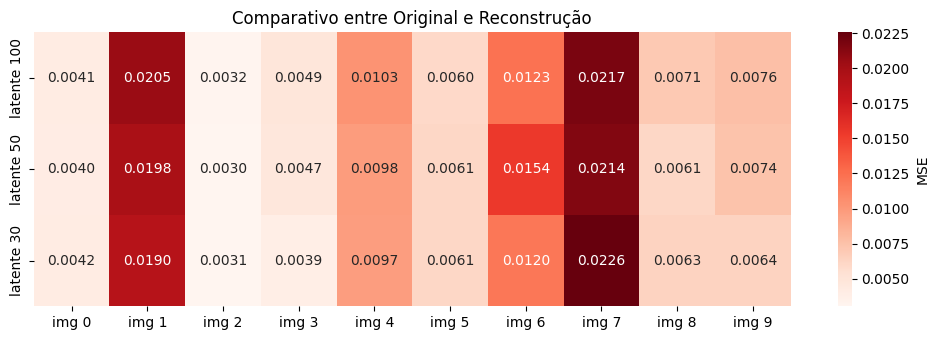

In [52]:
import seaborn as sns

matriz = np.array([resultados[ld][1].numpy() for ld in latent_dims])  # (3, 10)

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(matriz, annot=True, fmt=".4f", cmap="Reds",
            xticklabels=[f"img {i}" for i in range(10)],
            yticklabels=[f"latente {ld}" for ld in latent_dims],
            cbar_kws={"label": "MSE"}, ax=ax)
ax.set_title("Comparativo entre Original e Reconstrução")
plt.tight_layout()
plt.savefig("mse_heatmap.png", dpi=150)
plt.show()

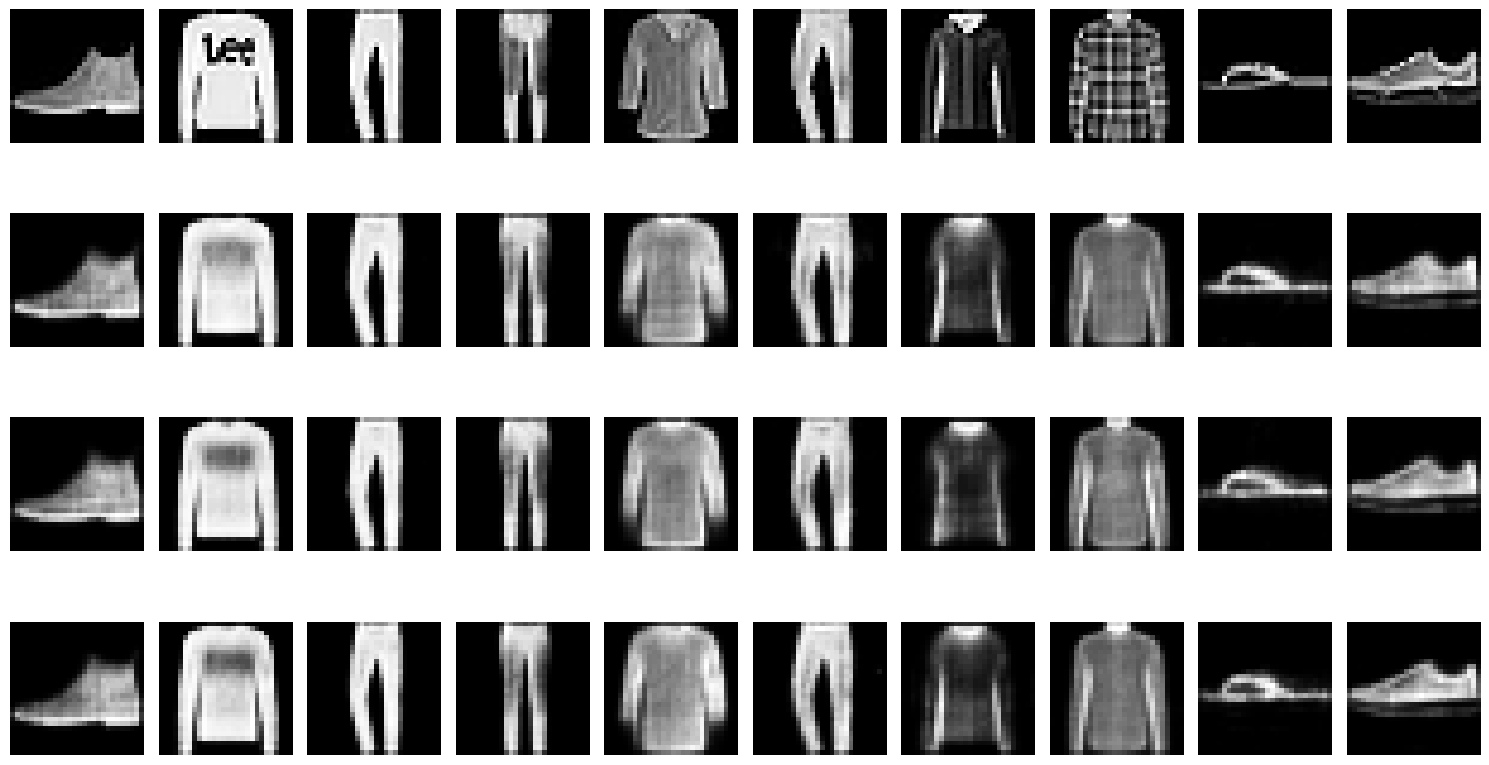

In [53]:
fig, axes = plt.subplots(len(latent_dims) + 1, 10, figsize=(15, 2.2*(len(latent_dims)+1)))
for i in range(10):
    axes[0, i].imshow(imgs_fixas[i,0].cpu(), cmap='gray')
    axes[0, i].axis('off')
axes[0, 0].set_ylabel("Original", fontsize=12)
for r, ld in enumerate(latent_dims, start=1):
    rec = resultados[ld][0]
    for i in range(10):
        axes[r, i].imshow(rec[i,0], cmap='gray')
        axes[r, i].axis('off')
    axes[r, 0].set_ylabel(f"Latente {ld}", fontsize=12)

plt.tight_layout()
plt.savefig("reconstrucoes_autoencoder.png", dpi=150)
plt.show()

## B.

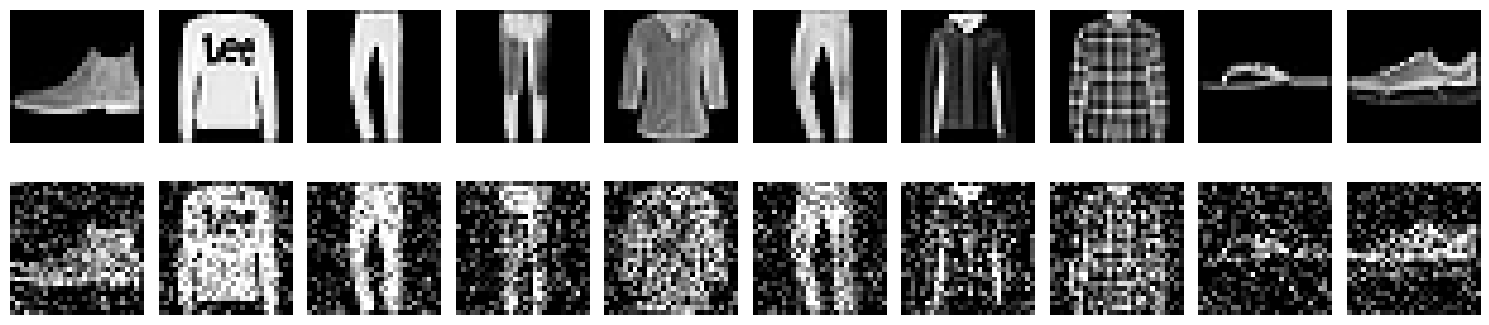

In [54]:
def adicionar_ruido(imagens, intensidade=0.3):
    ruido = torch.randn_like(imagens) * intensidade
    imagens_ruidosas = imagens + ruido

    return torch.clamp(imagens_ruidosas, 0.0, 1.0)


# Aplicar ruído às mesmas 10 imagens da letra (a)
torch.manual_seed(42)

imgs_ruidosas = adicionar_ruido(imgs_fixas)

# Comparar imagens originais e ruidosas
fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):
    axes[0, i].imshow(imgs_fixas[i, 0].cpu(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(imgs_ruidosas[i, 0].cpu(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Ruidosa")

plt.tight_layout()
plt.show()

In [55]:
def treinar_denoising(model, train_loader, epochs=15, lr=1e-3):
    model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    for ep in range(epochs):
        model.train()
        total = 0.0

        for x, _ in train_loader:
            x = x.to(device)

            # Adiciona ruído às imagens de entrada
            x_ruidoso = adicionar_ruido(x)

            optimizer.zero_grad()

            # Reconstrói a imagem a partir da versão ruidosa
            x_hat, _ = model(x_ruidoso)

            # Compara a reconstrução com a imagem original
            loss = criterion(x_hat, x)

            loss.backward()
            optimizer.step()

            total += loss.item() * x.size(0)

        print(f"Época {ep+1:02d} | loss MSE: {total/len(train_loader.dataset):.6f}")

In [56]:
# Criar um novo autoencoder
modelo_denoising = AutoencoderDenso(latent_dim=50)

# Treinar com imagens ruidosas
treinar_denoising(
    modelo_denoising,
    train_loader,
    epochs=15,
    lr=1e-3
)

Época 01 | loss MSE: 0.043404
Época 02 | loss MSE: 0.023535
Época 03 | loss MSE: 0.020927
Época 04 | loss MSE: 0.019312
Época 05 | loss MSE: 0.018242
Época 06 | loss MSE: 0.017325
Época 07 | loss MSE: 0.016652
Época 08 | loss MSE: 0.016122
Época 09 | loss MSE: 0.015676
Época 10 | loss MSE: 0.015319
Época 11 | loss MSE: 0.014959
Época 12 | loss MSE: 0.014646
Época 13 | loss MSE: 0.014451
Época 14 | loss MSE: 0.014175
Época 15 | loss MSE: 0.013963


MSE médio: 0.012727


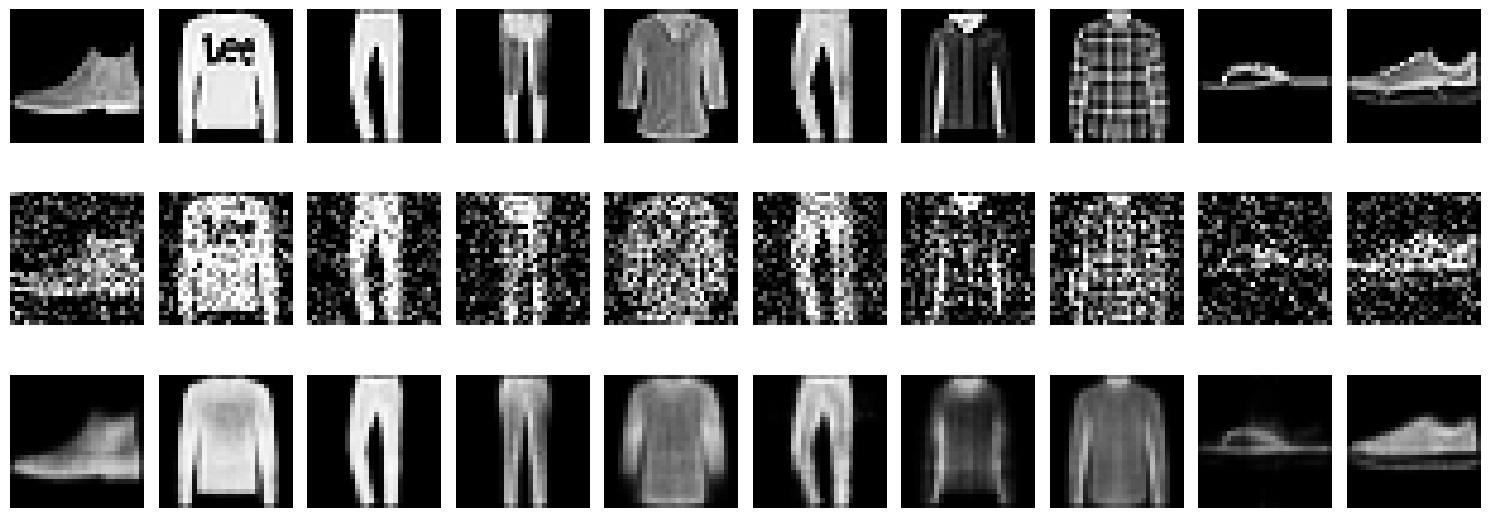

In [57]:
# Avaliar o modelo
modelo_denoising.eval()

with torch.no_grad():
    reconstruidas, _ = modelo_denoising(imgs_ruidosas)

# Calcular o erro em relação às imagens originais
mse = ((reconstruidas - imgs_fixas) ** 2).mean(dim=[1, 2, 3])

print(f"MSE médio: {mse.mean().item():.6f}")

# Visualizar os resultados
fig, axes = plt.subplots(3, 10, figsize=(15, 6))

imagens = [
    imgs_fixas,
    imgs_ruidosas,
    reconstruidas
]

titulos = ["Original", "Ruidosa", "Reconstruída"]

for linha in range(3):
    for i in range(10):
        axes[linha, i].imshow(
            imagens[linha][i, 0].cpu(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[linha, i].axis("off")

    axes[linha, 0].set_ylabel(titulos[linha], fontsize=12)

plt.tight_layout()
plt.show()